# Agents 

In [ ]:

class TrafficAgent:
    def act(self, light):
        if light == "green":
            return "GO"
        elif light == "yellow":
            return "SLOW DOWN"
        elif light == "red":
            return "STOP"

agent = TrafficAgent()
for light in ["green", "red", "yellow", "green", "red"]:
    print(light, "->", agent.act(light))

green -> GO
red -> STOP
yellow -> SLOW DOWN
green -> GO
red -> STOP


In [ ]:
class ModelBasedAgent:
    def __init__(self):
        self.previous_temp = None          # memory starts empty

    def act(self, temp):
        # update memory: is it rising?
        rising = self.previous_temp is not None and temp > self.previous_temp
        self.previous_temp = temp          # remember for next time

        # rules (now they can use the memory)
        if temp > 75:
            return "AC ON"
        elif temp > 70 and rising:
            return "AC ON early (rising)"
        elif temp < 65:
            return "HEATER ON"
        else:
            return "DO NOTHING"

agent = ModelBasedAgent()
for t in [68, 70, 72, 74, 76]:
    print(t, "->", agent.act(t))

In [ ]:
class GoalAgent:
    def __init__(self, goal):
        self.goal = goal                   # fixed knowledge

    def act(self, position):
        if position < self.goal:
            return "RIGHT"
        elif position > self.goal:
            return "LEFT"
        else:
            return "DONE"

    def run(self, start):
        position = start
        while True:
            action = self.act(position)
            print("At", position, "->", action)
            if action == "DONE":
                break
            position = position + 1 if action == "RIGHT" else position - 1

GoalAgent(goal=5).run(start=1)

In [9]:
phones = [
    {"name": "A", "camera": 8, "battery": 6, "price": 9},
    {"name": "B", "camera": 9, "battery": 5, "price": 7},
    {"name": "C", "camera": 9, "battery": 9, "price": 11},
]

def utility(phone):
    return 0.5 * phone["camera"] + 0.3 * phone["battery"] - 0.2 * phone["price"]

def utility_agent(phones, budget):
    # 1. throw away options that are not allowed
    feasible = [p for p in phones if p["price"] <= budget]
    if not feasible:
        return "NONE"
    # 2. pick the highest utility
    return max(feasible, key=utility)["name"]

for p in phones:
    print(p["name"], "utility =", round(utility(p), 2))

for budget in [12, 8, 3]:
    print("budget", budget, "->", utility_agent(phones, budget))

A utility = 4.0
B utility = 4.6
C utility = 5.0
budget 12 -> C
budget 8 -> B
budget 3 -> NONE


In [ ]:
routes = [
    {"name": "R1", "time_min": 18, "battery_used": 35, "risk": 0.10},
    {"name": "R2", "time_min": 12, "battery_used": 55, "risk": 0.30},
    {"name": "R3", "time_min": 25, "battery_used": 20, "risk": 0.05},
    {"name": "R4", "time_min": 15, "battery_used": 40, "risk": 0.20},
]

def utility(route):
    return 100 - (2 * route["time_min"]) - (0.5 * route["battery_used"]) - (80 * route["risk"])

def utility_agent(routes, battery_left):
    best_name, best_score = "RETURN_TO_BASE", -9999
    for r in routes:
        if r["battery_used"] > battery_left:
            continue                      # discard: not enough battery
        if utility(r) > best_score:
            best_name, best_score = r["name"], utility(r)
    return best_name

for r in routes:
    print(r["name"], "utility =", utility(r))

for battery in [100, 50, 15]:
    print("battery_left =", battery, "->", utility_agent(routes, battery))

R1 utility = 38.5
R2 utility = 24.5
R3 utility = 36.0
R4 utility = 34.0
battery_left = 100 -> R1
battery_left = 50 -> R1
battery_left = 15 -> RETURN_TO_BASE


# BFS DFS AND SHI

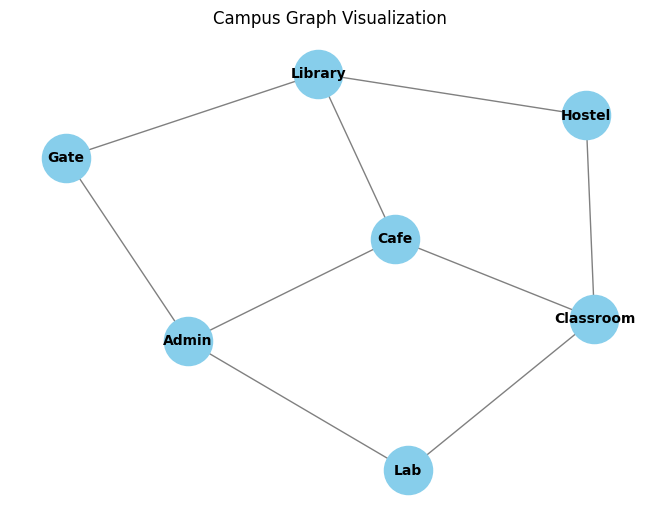

In [1]:
import matplotlib.pyplot as plt  
import networkx as nx


graph_dict = {
    "Gate": ["Admin", "Library"],
    "Admin": ["Lab", "Cafe"],
    "Library": ["Hostel", "Cafe"],
    "Lab": ["Classroom"],  
    "Cafe": ["Classroom"],  
    "Hostel": ["Classroom"],
}


G = nx.Graph(graph_dict)

pos = nx.spring_layout(G)


nx.draw(
    G,
    pos,  
    with_labels=True,
    node_color="skyblue",
    node_size=1200,  
    font_size=10,
    font_weight="bold",
    edge_color="gray",
)

plt.title("Campus Graph Visualization")
plt.show()


In [2]:
import heapq
graph_dict = {
    "Gate": ["Admin", "Library"],
    "Admin": ["Lab", "Cafe"],
    "Library": ["Hostel", "Cafe"],
    "Lab": ["Classroom"],  
    "Cafe": ["Classroom"],  
    "Hostel": ["Classroom"],
}

def dfs(start , goal , graph , visited = None , path = None):
    
    if not visited:
        visited = set()
    if not path: 
        path = [start]
    
    visited.add(start)
    if start == goal:
        return path
    
    for neighbor in graph.get(start, []):
        if neighbor not in visited:
            result = dfs(neighbor , goal , graph , visited , path + [neighbor])
            
            if result:
                return result
                
            
    return None


def bfs(start , goal , graph):
    queue = [(start, [start])]
    visited = [start]
    
    while queue:
        
        currnode , path = queue.pop(0)
        if currnode == goal:
            return path
        for n in graph.get(currnode , []):
            if n not in visited:
                visited.append(n)
                queue.append((n , path + [n]))
    return None

answerdfs = dfs("Gate" , "Hostel" , graph_dict)
answerbfs = bfs("Gate" , "Hostel" , graph_dict)
print("DFS:", answerdfs)
print("BFS:", answerbfs)


DFS: ['Gate', 'Library', 'Hostel']
BFS: ['Gate', 'Library', 'Hostel']


In [3]:
graph_weighted = {
    "Gate": [("Admin", 2), ("Library", 5)],
    "Admin": [("Lab", 3), ("Cafeteria", 6)],
    "Library": [("Cafeteria", 2), ("Hostel", 4)],
    "Lab": [("Classroom", 5)],
    "Cafeteria": [("Classroom", 2)],
    "Hostel": [("Classroom", 1)],
    "Classroom": []
}
import heapq

def ucs(graph , start , goal):
    visited = set()
    queue = [(0, start, [start])]
    
    while queue:
        cost, node ,path = queue.pop(0)
        
        if node == goal:
            return path , cost
        if node not in visited:
            visited.add(node)
        for n,c in graph.get(node , []):
            if n not in visited:
                visited.add(n)
                heapq.heappush(queue , (cost + c , n , path + [n]))
    return None

answerucs = ucs(graph_weighted , "Gate" , "Classroom")
print("UCS:", answerucs)

UCS: (['Gate', 'Admin', 'Lab', 'Classroom'], 10)


In [11]:
import heapq

# Node names: S=Start, G=Goal, A/B/C/D/E = intermediate waypoints
graph = {
    "S": {"A": 2, "B": 5},
    "A": {"C": 2, "D": 4},
    "B": {"D": 1, "E": 3},
    "C": {"D": 1, "G": 7},
    "D": {"G": 3},
    "E": {"G": 2},
    "G": {},
}
# heuristic: estimated cost from each node to the goal G
heuristic = {"S": 7, "A": 6, "B": 4, "C": 5, "D": 3, "E": 2, "G": 0}

def astar(graph, heuristic, start, goal):
    # Each priority queue entry: (f_score, g_score, current_node, path_so_far)
    # f_score = g_score + heuristic[node]  (total estimated cost)
    # g_score = actual cost paid from start to current_node
    pq = [(heuristic[start], 0, start, [start])]   # (f, g, node, path)
    best_g = {}   # best known g_score seen for each node
    while pq:
        f_score, g_score, node, path = heapq.heappop(pq)   # expand lowest f first
        if node == goal:
            return path, g_score
        if node in best_g and best_g[node] <= g_score:
            continue   # already found a cheaper path to this node
        best_g[node] = g_score
        for neighbor, edge_weight in graph[node].items():
            new_g = g_score + edge_weight
            heapq.heappush(pq, (new_g + heuristic[neighbor], new_g, neighbor, path + [neighbor]))
    return None, None

path, cost = astar(graph, heuristic, "S", "G")
print("Path:", " -> ".join(path))
print("Total cost:", cost)

Path: S -> A -> C -> D -> G
Total cost: 8


In [10]:
import heapq

# Node names: S=Start, G=Goal, A/B/C/D/E = intermediate waypoints
graph = {
    "S": {"A": 4, "B": 3},
    "A": {"C": 5, "D": 2},
    "B": {"D": 4, "E": 3},
    "C": {"G": 3},
    "D": {"G": 6, "E": 2},
    "E": {"G": 2},
    "G": {},
}
# heuristic: estimated cost from each node to the goal G
heuristic = {"S": 8, "A": 6, "B": 5, "C": 3, "D": 4, "E": 2, "G": 0}

def greedy(graph, heuristic, start, goal):
    # Each priority queue entry: (heuristic_value, current_node, path_so_far, cost_so_far)
    # Greedy picks the node with the smallest heuristic (ignores actual cost paid)
    pq = [(heuristic[start], start, [start], 0)]   # (h_val, node, path, cost)
    visited = set()
    while pq:
        h_val, node, path, cost = heapq.heappop(pq)   # expand lowest heuristic first
        if node in visited:
            continue
        visited.add(node)
        if node == goal:
            return path, cost
        for neighbor, edge_weight in graph[node].items():
            heapq.heappush(pq, (heuristic[neighbor], neighbor, path + [neighbor], cost + edge_weight))
    return None, None

path, cost = greedy(graph, heuristic, "S", "G")
print("Path:", " -> ".join(path))
print("Total cost:", cost)

Path: S -> B -> E -> G
Total cost: 8


In [ ]:
import heapq

# Graph of a mall: nodes are locations, edge weights are travel times (minutes)
graph = {
    "Entrance":     {"Cinema": 4, "Food court": 2},
    "Cinema":       {"Parking hall": 3},
    "Food court":   {"Toy shop": 4, "Bookstore": 3},
    "Parking hall": {"Exit gate": 6},
    "Toy shop":     {"Exit gate": 4},
    "Bookstore":    {"Exit gate": 2},
    "Exit gate":    {},
}
# heuristic: estimated remaining time (minutes) from each location to the Exit gate
heuristic = {"Entrance": 6, "Cinema": 4, "Food court": 5, "Parking hall": 2,
             "Toy shop": 3, "Bookstore": 2, "Exit gate": 0}

def astar(graph, heuristic, start, goal):
    # Each priority queue entry: (f_score, g_score, current_node, path_so_far)
    # f_score = g_score + heuristic[node]  (total estimated time)
    # g_score = actual time spent from start to current_node
    pq = [(heuristic[start], 0, start, [start])]   # (f, g, node, path)
    best_g = {}   # best known g_score seen for each node
    while pq:
        f_score, g_score, node, path = heapq.heappop(pq)   # expand lowest f first
        if node == goal:
            return path, g_score
        if node in best_g and best_g[node] <= g_score:
            continue   # already found a faster path to this location
        best_g[node] = g_score
        for neighbor, edge_weight in graph[node].items():
            new_g = g_score + edge_weight
            heapq.heappush(pq, (new_g + heuristic[neighbor], new_g, neighbor, path + [neighbor]))
    return None, None

path, cost = astar(graph, heuristic, "Entrance", "Exit gate")
print("Path:", " -> ".join(path))
print("Total time:", cost, "minutes")